# Semi-Supervised and Positive-Unlabeled Fitting

This notebook demonstrates the Phase 5 (v0.4 roadmap) additions: semi-supervised fitting
(`fit(X, labels=...)` with `-1` for unknown rows) on every mixture family via the shared
`BaseMixture`, and `PositiveUnlabeledMixture` for positive-unlabeled (PU) learning.

See the [Semi-Supervised and Positive-Unlabeled Fitting](../user-guide/semi-supervised-pu.md)
user guide page for the terms (SCAR, mixture proportion estimation, `anchor`).


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import os

os.chdir('../')

from tgmm import GaussianMixture, StudentTMixture, PositiveUnlabeledMixture
from tgmm.metrics import ClusteringMetrics
from tgmm.plotting import plot_gmm

random_state = 42


## Part 1: semi-supervised fitting on three overlapping blobs

Three overlapping 2-D blobs where unsupervised EM's cluster <-> class correspondence is
genuinely ambiguous. We compare fits at 5%, 20%, and 100% of rows labeled, against plain
unsupervised EM (0% labeled) on the same data.


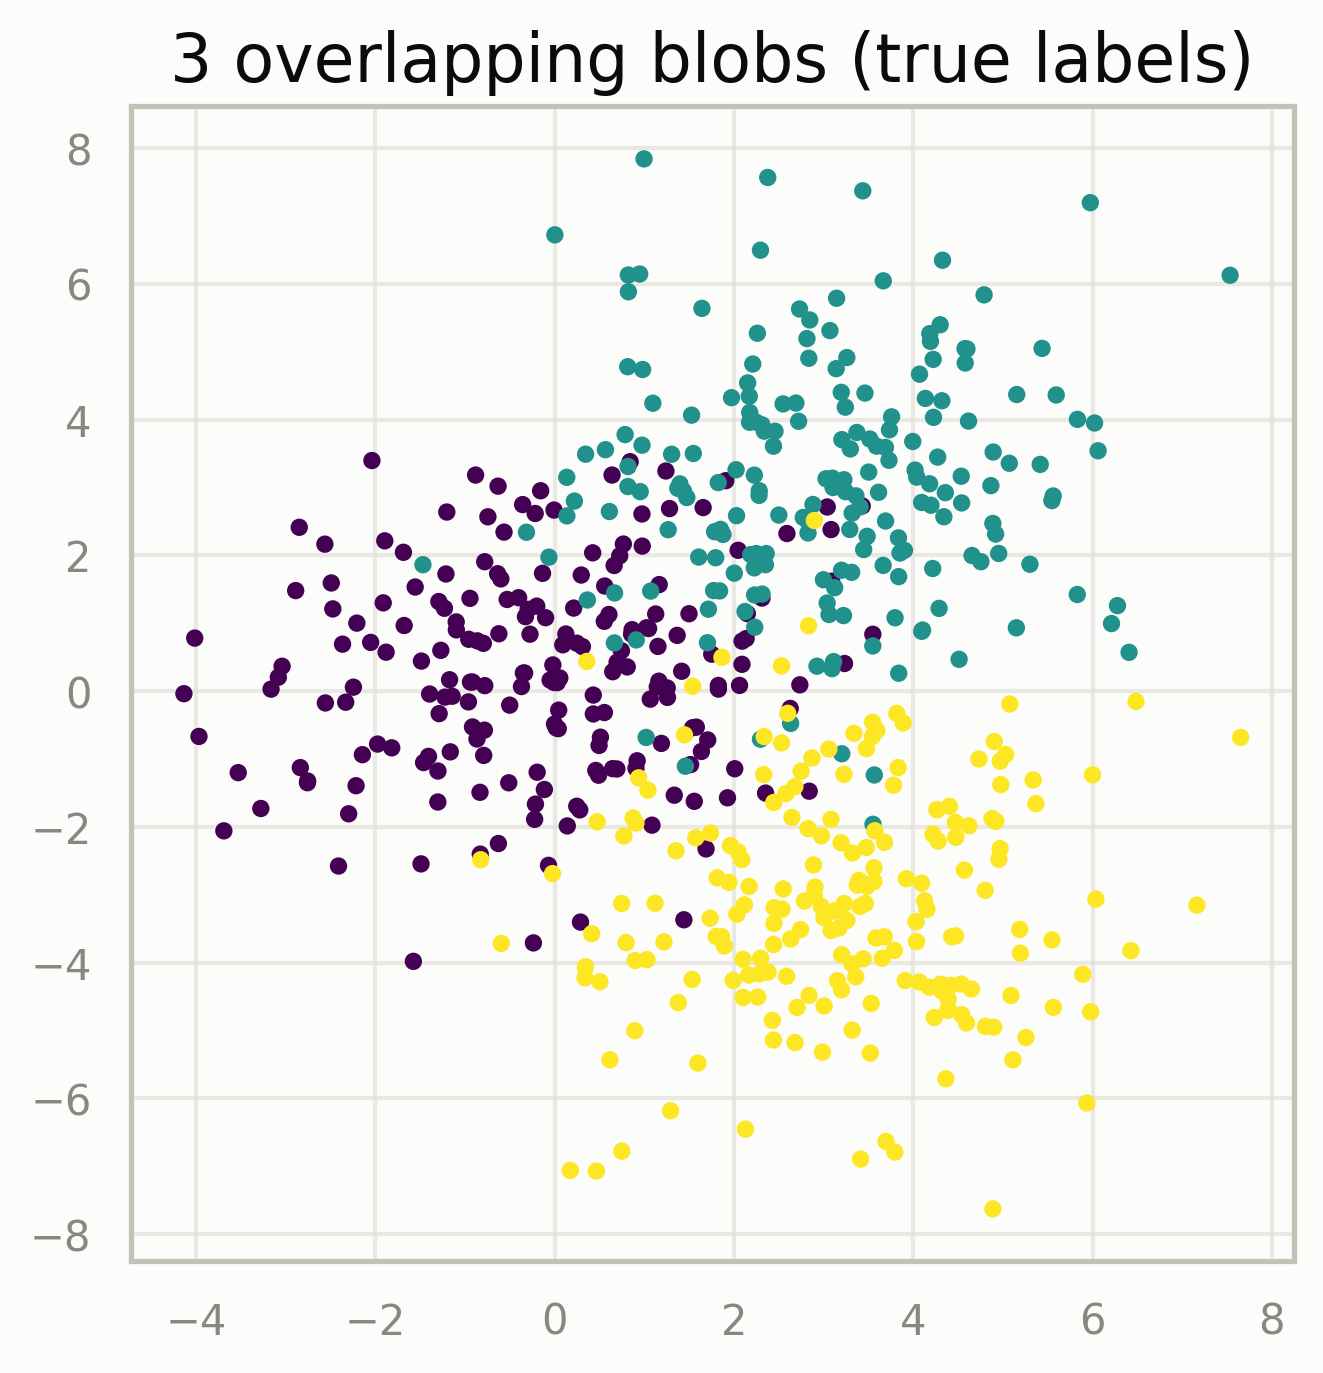

In [2]:
gen = torch.Generator().manual_seed(random_state)
n_per = 200
true_centers = torch.tensor([[0.0, 0.0], [3.0, 3.0], [3.0, -3.0]])
X = torch.cat([
    torch.randn(n_per, 2, generator=gen) * 1.6 + true_centers[0],
    torch.randn(n_per, 2, generator=gen) * 1.6 + true_centers[1],
    torch.randn(n_per, 2, generator=gen) * 1.6 + true_centers[2],
])
true_labels = torch.cat([torch.full((n_per,), k) for k in range(3)])

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=true_labels, cmap='viridis', s=10)
plt.title('3 overlapping blobs (true labels)')
plt.show()


In [3]:
def partial_labels(labels, frac, seed):
    gen = torch.Generator().manual_seed(seed)
    mask = torch.rand(labels.shape[0], generator=gen) < frac
    return torch.where(mask, labels, torch.full_like(labels, -1)), mask

# init_means='random' + n_init=1 (rather than the usual kmeans + n_init>1)
# so unsupervised EM's local-optimum quality genuinely depends on luck --
# otherwise a good initialization alone already resolves this data well
# regardless of labels, since ARI is itself invariant to how clusters are
# *numbered* (only labels fix that, which ARI doesn't measure).
label_fracs = [0.0, 0.05, 0.20, 1.0]
aris_by_frac = {frac: [] for frac in label_fracs}
example_models = {}

for seed in range(10):
    for frac in label_fracs:
        labels = None if frac == 0.0 else partial_labels(true_labels, frac, seed=100 + seed)[0]
        gmm = GaussianMixture(n_components=3, init_means='random', random_state=seed, n_init=1, max_iter=200)
        gmm.fit(X, labels=labels)
        aris_by_frac[frac].append(ClusteringMetrics.adjusted_rand_score(true_labels, gmm.predict(X)))
        if seed == 0:
            example_models[frac] = gmm

for frac in label_fracs:
    vals = aris_by_frac[frac]
    print(f'{int(frac*100):3d}% labeled: mean ARI = {sum(vals)/len(vals):.3f} (over 10 random-init seeds)')


  0% labeled: mean ARI = 0.434 (over 10 random-init seeds)
  5% labeled: mean ARI = 0.516 (over 10 random-init seeds)
 20% labeled: mean ARI = 0.698 (over 10 random-init seeds)
100% labeled: mean ARI = 0.704 (over 10 random-init seeds)


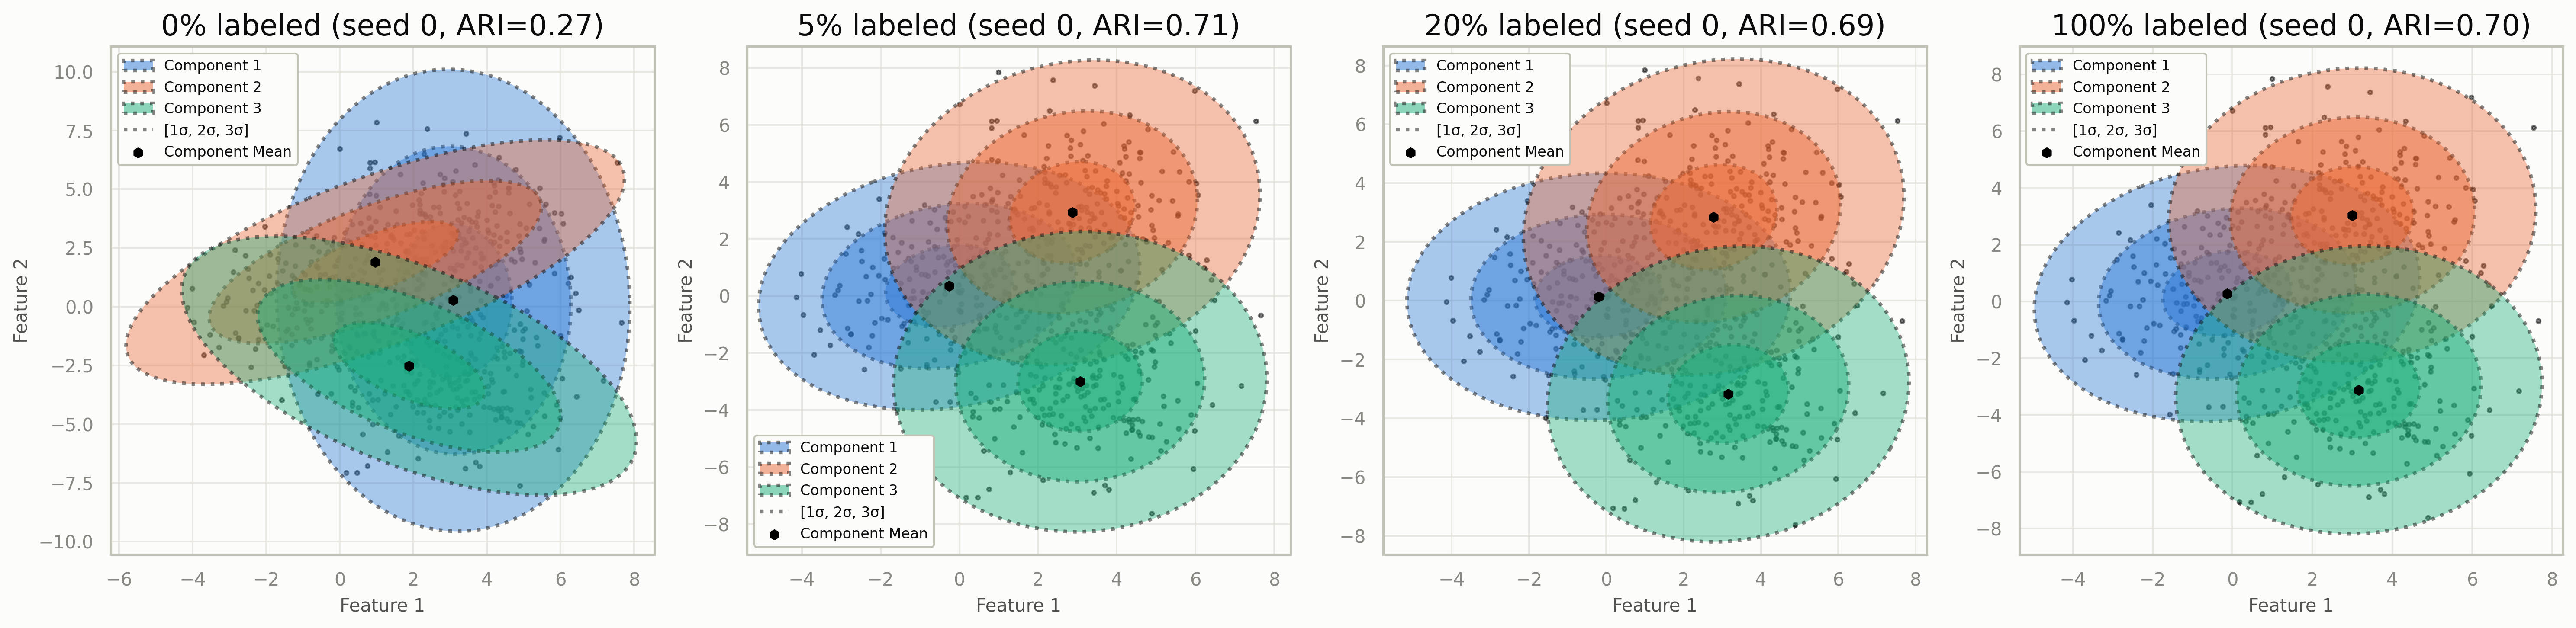

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, frac in zip(axes, label_fracs):
    gmm = example_models[frac]
    ari = ClusteringMetrics.adjusted_rand_score(true_labels, gmm.predict(X))
    plot_gmm(X, gmm=gmm, ax=ax, title=f'{int(frac*100)}% labeled (seed 0, ARI={ari:.2f})')
plt.tight_layout()
plt.show()


Even a handful of labels (5-20%) measurably improves cluster recovery over plain
unsupervised EM on this ambiguous, overlapping data (here, deliberately run from a single
random initialization so unsupervised EM's local-optimum quality varies -- with a strong
initializer like k-means and several restarts, as `GaussianMixture` uses by default, plain
unsupervised EM would already resolve this particular dataset well on its own, and the only
thing labels would add is knowing *which* cluster is which class, which `adjusted_rand_score`
itself can't measure since it's invariant to how clusters are numbered).


## Part 2: positive-unlabeled learning on a "cancer cells vs. everything else" simulation

A `StudentTMixture`-based PU model: a minority "cancer cell" population with heavier-tailed
within-class variation (some genuinely atypical cells), embedded in a larger population of
several other, unlabeled cell types. Only a small fraction of the true positives are
confirmed-labeled; everything else is unlabeled.


In [5]:
d = 10
gen = torch.Generator().manual_seed(random_state)

n_positive_true = 150
n_negative_true = 600
pi_true = n_positive_true / (n_positive_true + n_negative_true)

positive_center = torch.full((d,), 3.0)
X_positive = torch.randn(n_positive_true, d, generator=gen) * 1.0 + positive_center

# 2 other, unlabeled cell types (the 'negative' population)
neg_centers = [torch.full((d,), -3.0), torch.full((d,), -3.0) * torch.tensor([1.0]*3 + [-1.0]*7)]
X_negative = torch.cat([
    torch.randn(n_negative_true // 2, d, generator=gen) * 1.2 + c for c in neg_centers
])

X = torch.cat([X_positive, X_negative])
true_positive = torch.cat([
    torch.ones(n_positive_true, dtype=torch.bool), torch.zeros(X_negative.shape[0], dtype=torch.bool),
])

# Only 15% of the true positives are confirmed-labeled (SCAR: a uniform random subsample).
label_frac = 0.15
gen2 = torch.Generator().manual_seed(random_state + 1)
positive_indices = true_positive.nonzero(as_tuple=True)[0]
n_labeled = int(label_frac * positive_indices.numel())
labeled_idx = positive_indices[torch.randperm(positive_indices.numel(), generator=gen2)[:n_labeled]]
positive_mask = torch.zeros(X.shape[0], dtype=torch.bool)
positive_mask[labeled_idx] = True

print(f'True class prior (fraction positive): {pi_true:.3f}')
print(f'Labeled positives: {positive_mask.sum().item()} / {true_positive.sum().item()} true positives')


True class prior (fraction positive): 0.200
Labeled positives: 22 / 150 true positives


In [6]:
pu = PositiveUnlabeledMixture(
    n_components_positive=1, n_components_negative=2, family='student_t',
    anchor='fixed', random_state=random_state, n_init=3, max_iter=200,
)
pu.fit(X, positive_mask)

pred_positive = pu.predict_positive(X)
tp = (pred_positive & true_positive).sum().item()
fp = (pred_positive & ~true_positive).sum().item()
fn = (~pred_positive & true_positive).sum().item()
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

print(f'Estimated class_prior_ (fraction of UNLABELED rows that are positive): {pu.class_prior_:.3f}')
print(f'True class prior:                                                      {pi_true:.3f}')
print(f'Held-out F1 on positive classification: {f1:.3f}')


/home/asp/Downloads/HeaDS/tgmm/tgmm/mixtures/base.py:735: UserWarning: With n_init=3 and random_state=42, initializations will use random states [42, 43, ..., 44]. The best initialization's random state will be stored in best_random_state_.
  warnings.warn(
/home/asp/Downloads/HeaDS/tgmm/tgmm/mixtures/base.py:784: UserWarning: Best result from random_state=42. To reproduce this specific result: use random_state=42 with n_init=1.
  warnings.warn(
/home/asp/Downloads/HeaDS/tgmm/tgmm/mixtures/base.py:1141: UserWarning: With n_init=3 and random_state=42, initializations will use random states [42, 43, ..., 44]. The best initialization's random state will be stored in best_random_state_.
  warnings.warn(


Estimated class_prior_ (fraction of UNLABELED rows that are positive): 0.171
True class prior:                                                      0.200
Held-out F1 on positive classification: 0.990


/home/asp/Downloads/HeaDS/tgmm/tgmm/mixtures/base.py:1177: UserWarning: Best result from random_state=42. To reproduce this specific result: use random_state=42 with n_init=1.
  warnings.warn(


### The positive-probability map

Projecting onto the first two dimensions (where the positive/negative separation is
strongest by construction): confirmed-labeled positives are marked with a star, and color
shows `predict_proba_positive` for every row -- the model's estimate of how likely each
*unlabeled* row is to actually be positive.


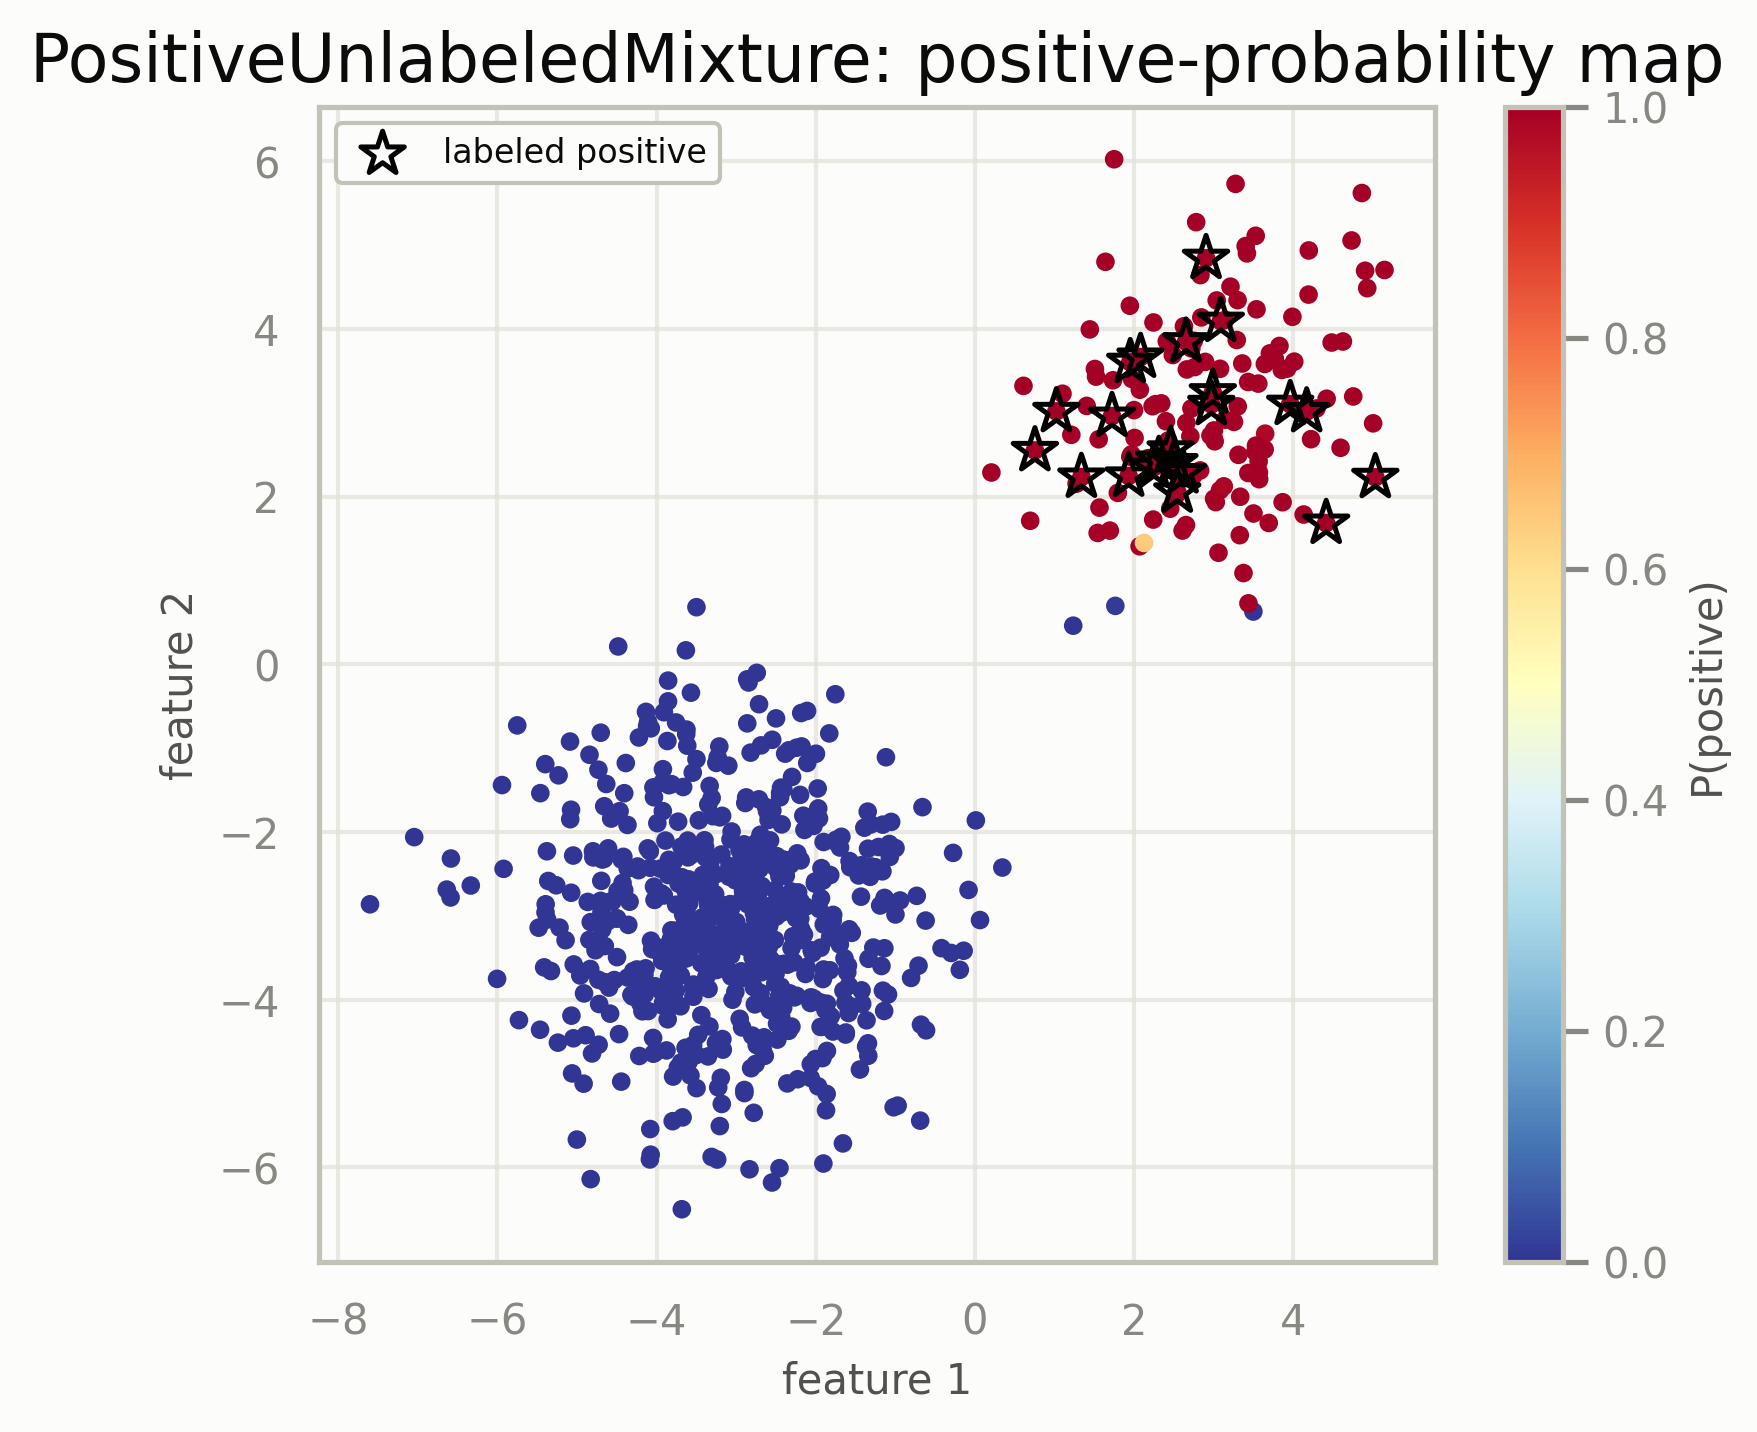

In [7]:
proba_positive = pu.predict_proba_positive(X)

plt.figure(figsize=(6, 5))
sc = plt.scatter(X[:, 0], X[:, 1], c=proba_positive, cmap='RdYlBu_r', s=12, vmin=0, vmax=1)
plt.scatter(X[positive_mask, 0], X[positive_mask, 1], marker='*', s=120,
            facecolors='none', edgecolors='black', linewidths=1.2, label='labeled positive')
plt.colorbar(sc, label='P(positive)')
plt.legend()
plt.title('PositiveUnlabeledMixture: positive-probability map')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.show()


## Summary

- Semi-supervised fitting (`fit(X, labels=...)` with `-1` for unknown) works on every tgmm
  mixture family, and a modest labeling budget (5-20%) can substantially improve cluster
  recovery on ambiguous, overlapping data.
- `PositiveUnlabeledMixture` recovers both the class prior (the fraction of unlabeled rows
  that are actually positive) and a per-row positive probability from only a small labeled
  positive subset, under the SCAR assumption -- useful whenever confirming a negative is
  expensive or impossible, but confirming a positive is not.
